# 04 · Statistical Analysis
**Education Insights Lab: Diagnosing Educational Opportunity and Outcomes**

**Purpose.** Turn the visual impressions from EDA into formal estimates, with uncertainty and tests, and answer the primary question:

> After accounting for socioeconomic conditions, are per-pupil expenditure and broadband access still associated with mathematics proficiency in US K-12 schools?

**Why these methods (each is chosen by the question, not because it was taught):**

| Question | Method | Why this method |
|---|---|---|
| How strong is each pairwise link, and how certain? | Pearson / Spearman correlation with Fisher-z confidence intervals | Quantifies strength with uncertainty; Spearman checks robustness to shape |
| Do math scores differ by Title I status? | Welch ANOVA, Kruskal-Wallis, Tukey post-hoc, eta² | Welch ANOVA and Kruskal-Wallis do not assume equal variances or normality; Levene's test (p = 0.19) supports equal variances, so Tukey HSD is appropriate for the pairwise comparisons; eta² gives the effect size |
| Are STEM certification and Title I associated? | Chi-square test of independence, Cramér's V | Both variables are categorical (the brief's own example) |
| **Do spending and broadband matter after controlling for poverty?** | **Nested multiple regression** with robust standard errors, robust Wald F-tests, bootstrap | **Directly answers the primary question: tests each variable's association while holding the others fixed** |
| Does the spending association differ by poverty level? | Interaction model | Tests whether spending "works differently" in poor versus rich schools |
| Are the conclusions fragile? | Diagnostics and robustness checks | Shows results do not depend on a few odd rows or one school level |

**Contents**
1. Setup and hypotheses
2. Assumption checks
3. Correlation analysis with confidence intervals
4. Group comparisons: Title I, locale and STEM
5. Nested regression: the core analysis
6. Standardised effects and multicollinearity
7. Bootstrap confidence intervals
8. Interaction: does the spending association depend on poverty?
9. Model diagnostics
10. Robustness checks
11. Summary of statistical findings

## 1. Setup and hypotheses

**Formal hypotheses** (for each predictor *j* in the regression, with the other variables held fixed):
- **H0:** the coefficient β<sub>j</sub> = 0 (no association with math proficiency after accounting for the other variables)
- **H1:** β<sub>j</sub> ≠ 0

Significance level α = 0.05, two-sided. With about 4,600 schools, even tiny effects can be "statistically significant", so I report **effect sizes and confidence intervals**, not p-values alone.

In [1]:
import sys, warnings
sys.path.append('../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

from utils import PATHS, set_style, save_fig, save_json, PALETTE, RANDOM_STATE
from data_cleaning import load_k12
set_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

k12 = load_k12()
n = len(k12)
results = {'n': n}
print(f'{n:,} K-12 schools')

4,642 K-12 schools


## 2. Assumption checks

Linear regression and the correlation tests assume (roughly) a symmetric, well-behaved outcome and independent observations. I check the outcome now and the **residuals** in section 9 (the residuals are what the assumptions are really about).

Math proficiency: mean = 58.7, sd = 16.0, skew = -0.03, excess kurtosis = -0.32


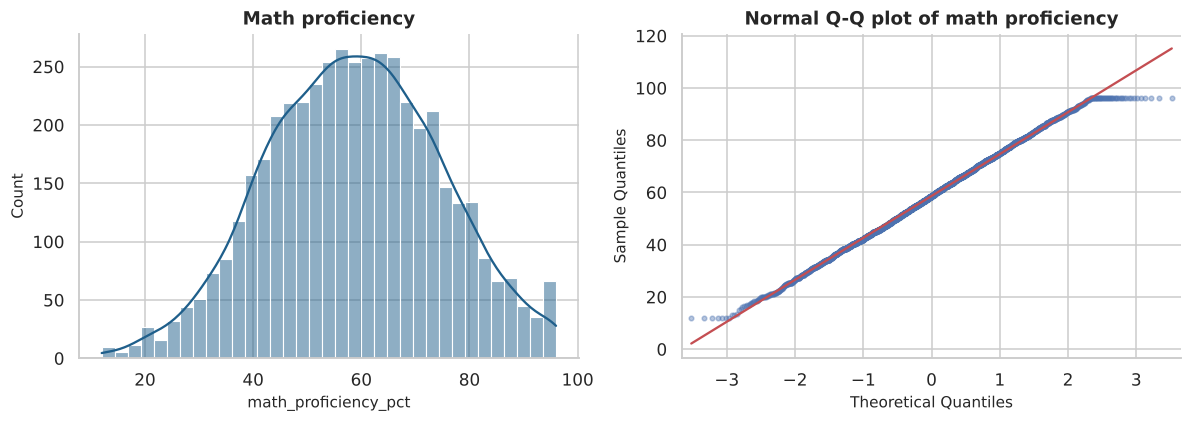

In [2]:
y = k12['math_proficiency_pct']
print(f'Math proficiency: mean = {y.mean():.1f}, sd = {y.std():.1f}, skew = {y.skew():.2f}, excess kurtosis = {y.kurt():.2f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(y, kde=True, bins=35, ax=ax[0], color=PALETTE['primary']); ax[0].set_title('Math proficiency')
sm.qqplot(y, line='s', ax=ax[1], markersize=3, alpha=.4); ax[1].set_title('Normal Q-Q plot of math proficiency')
plt.tight_layout(); save_fig('04_target_normality'); plt.show()

The outcome is close to symmetric (skewness near zero). The Q-Q plot follows the line through the middle with slight bends in the tails, consistent with the ceiling at 96%. With n in the thousands the central-limit theorem makes the mean-based tests robust to small departures, and I use heteroskedasticity-robust standard errors in the regression. The independence assumption is a limitation I note: schools in the same state or district may resemble one another (see README limitations).

## 3. Correlation analysis with confidence intervals

A correlation coefficient without an interval hides how certain it is. I use the Fisher z-transformation to get a 95% CI for each Pearson *r*.

,pearson_r,ci_low,ci_high,spearman_rho,p_value
variable,,,,,
Free/reduced lunch (%),-0.588,-0.606,-0.568,-0.581,0.000
Chronic absenteeism (%),-0.432,-0.455,-0.408,-0.414,0.000
Student-teacher ratio,-0.116,-0.144,-0.087,-0.114,0.000
English learners (%),-0.046,-0.074,-0.017,-0.041,0.002
Special education (%),-0.013,-0.042,0.016,-0.015,0.374
Log enrollment,0.006,-0.022,0.035,0.005,0.661
Per-pupil spending ($k),0.287,0.261,0.314,0.269,0.000
Broadband access (%),0.449,0.426,0.472,0.438,0.000


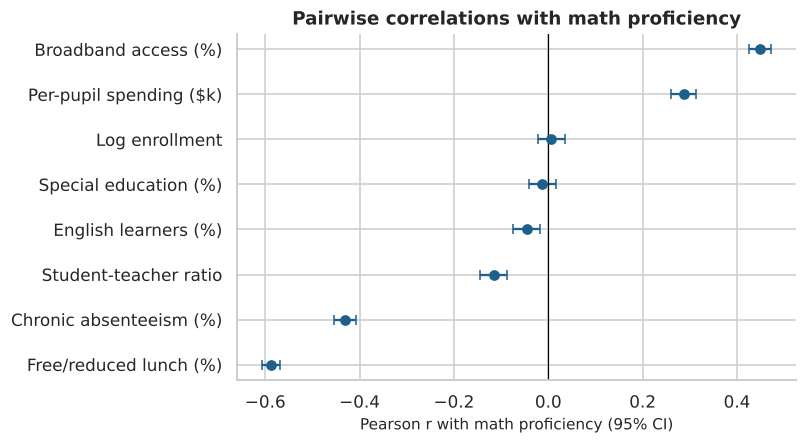

In [3]:
def fisher_ci(r, n, alpha=0.05):
    z = np.arctanh(r); se = 1 / np.sqrt(n - 3); zc = stats.norm.ppf(1 - alpha / 2)
    return np.tanh(z - zc * se), np.tanh(z + zc * se)

labels = {
    'percent_free_reduced_lunch': 'Free/reduced lunch (%)',
    'broadband_access_pct': 'Broadband access (%)',
    'ppe_k': 'Per-pupil spending ($k)',
    'student_teacher_ratio': 'Student-teacher ratio',
    'log_enrollment': 'Log enrollment',
    'chronic_absenteeism_pct': 'Chronic absenteeism (%)',
    'english_learner_pct': 'English learners (%)',
    'special_education_pct': 'Special education (%)',
}
rows = []
for c, lab in labels.items():
    r, p = stats.pearsonr(k12[c], y)
    rho, _ = stats.spearmanr(k12[c], y)
    lo, hi = fisher_ci(r, n)
    rows.append({'variable': lab, 'pearson_r': r, 'ci_low': lo, 'ci_high': hi, 'spearman_rho': rho, 'p_value': p})
corr_tbl = pd.DataFrame(rows).set_index('variable').sort_values('pearson_r')
display(corr_tbl.round(3))

results['corr'] = {c: {'pearson': float(stats.pearsonr(k12[c], y)[0]),
                       'ci_low': float(fisher_ci(stats.pearsonr(k12[c], y)[0], n)[0]),
                       'ci_high': float(fisher_ci(stats.pearsonr(k12[c], y)[0], n)[1]),
                       'spearman': float(stats.spearmanr(k12[c], y)[0])} for c in labels}

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.errorbar(corr_tbl['pearson_r'], range(len(corr_tbl)),
            xerr=[corr_tbl['pearson_r'] - corr_tbl['ci_low'], corr_tbl['ci_high'] - corr_tbl['pearson_r']],
            fmt='o', color=PALETTE['primary'], capsize=3)
ax.axvline(0, color='black', lw=.8); ax.set_yticks(range(len(corr_tbl))); ax.set_yticklabels(corr_tbl.index)
ax.set_xlabel('Pearson r with math proficiency (95% CI)'); ax.set_title('Pairwise correlations with math proficiency')
plt.tight_layout(); save_fig('04_correlation_cis'); plt.show()

**Reading.** Poverty has by far the strongest association with math proficiency (strongly negative); broadband is moderately positive; spending is moderately positive but smaller. The confidence intervals are narrow (large n), so the *ordering* is reliable. Pearson and Spearman agree closely, which means the links are not an artefact of a few extreme values or a curved shape.

These are **unadjusted** associations; the regression in section 5 is what answers the primary question.

## 4. Group comparisons

### 4.1 Math proficiency by Title I status (Welch ANOVA, Kruskal-Wallis, Tukey, effect size)

In [4]:
groups = k12.groupby('title_i_status')['math_proficiency_pct']
display(groups.agg(['count', 'mean', 'std']).round(2).sort_values('mean'))

samples = [g.values for _, g in groups]
lev = stats.levene(*samples)
welch = anova_oneway(k12['math_proficiency_pct'].values, groups=k12['title_i_status'].values, use_var='unequal')
kw = stats.kruskal(*samples)

# eta-squared (share of variance in math proficiency explained by Title I group)
grand = k12['math_proficiency_pct'].mean()
ss_between = sum(len(s) * (s.mean() - grand) ** 2 for s in samples)
ss_total = ((k12['math_proficiency_pct'] - grand) ** 2).sum()
eta2 = ss_between / ss_total

print(f'Levene (equal variances?)  : W = {lev.statistic:.2f}, p = {lev.pvalue:.3g}')
print(f'Welch ANOVA                : F = {welch.statistic:.1f}, p = {welch.pvalue:.3g}')
print(f'Kruskal-Wallis (non-param.): H = {kw.statistic:.1f}, p = {kw.pvalue:.3g}')
print(f'Effect size eta-squared    : {eta2:.3f}  ({eta2:.1%} of the variation in math proficiency)')

tuk = pairwise_tukeyhsd(k12['math_proficiency_pct'], k12['title_i_status'])
display(pd.DataFrame(tuk.summary().data[1:], columns=tuk.summary().data[0]))

results['title1'] = {'eta2': float(eta2), 'welch_p': float(welch.pvalue), 'kruskal_p': float(kw.pvalue),
                     'means': groups.mean().round(2).to_dict()}

,count,mean,std
title_i_status,,,
Title I Schoolwide,2180,51.68,14.25
Title I Targeted,945,58.86,14.25
Not Title I Eligible,767,67.22,13.55
Not Applicable,750,69.94,14.73


Levene (equal variances?)  : W = 1.58, p = 0.192
Welch ANOVA                : F = 422.6, p = 4.44e-210
Kruskal-Wallis (non-param.): H = 990.2, p = 2.42e-214
Effect size eta-squared    : 0.216  (21.6% of the variation in math proficiency)


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Not Applicable,Not Title I Eligible,-2.7219,0.0011,-4.5984,-0.8455,True
1,Not Applicable,Title I Schoolwide,-18.2600,0.0000,-19.8068,-16.7132,True
2,Not Applicable,Title I Targeted,-11.0811,0.0000,-12.8680,-9.2942,True
3,Not Title I Eligible,Title I Schoolwide,-15.5381,0.0000,-17.0721,-14.0040,True
4,Not Title I Eligible,Title I Targeted,-8.3591,0.0000,-10.1350,-6.5833,True
5,Title I Schoolwide,Title I Targeted,7.1789,0.0000,5.7558,8.6021,True


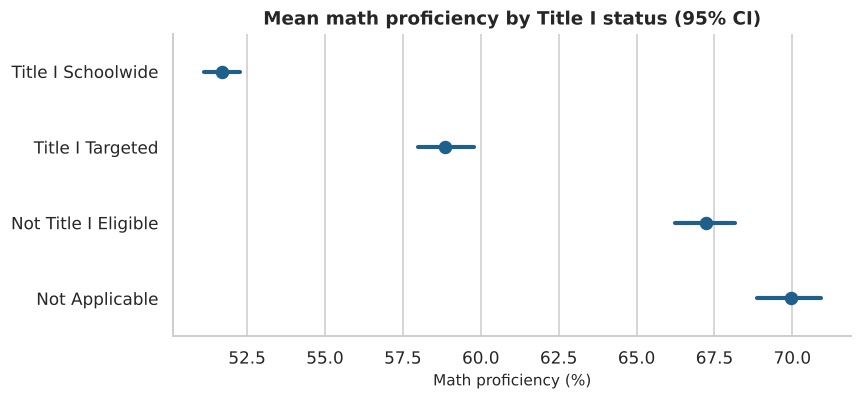

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = groups.mean().sort_values().index
sns.pointplot(data=k12, y='title_i_status', x='math_proficiency_pct', order=order, errorbar=('ci', 95),
              color=PALETTE['primary'], linestyle='none', ax=ax)
ax.set_title('Mean math proficiency by Title I status (95% CI)'); ax.set_xlabel('Math proficiency (%)'); ax.set_ylabel('')
plt.tight_layout(); save_fig('04_title1_means'); plt.show()

**Reading.** All three tests agree: math proficiency differs strongly by Title I status, and every pair of groups differs significantly in the Tukey comparison. (Levene's test does not reject equal variances, so Tukey's assumption is reasonable here; Welch ANOVA and Kruskal-Wallis act as robustness checks.) The effect size (eta²) shows how much of the school-to-school variation Title I status accounts for. Because Title I eligibility is *defined by* student poverty, this is largely the poverty gradient seen through an administrative label; it is a description of who is served, not evidence that the Title I programme lowers scores.

### 4.2 Is there a broadband gap across locales?

In [6]:
loc_groups = [g['broadband_access_pct'].values for _, g in k12.groupby('locale_group')]
kw_loc = stats.kruskal(*loc_groups)
grand_b = k12['broadband_access_pct'].mean()
eta2_loc = sum(len(s) * (s.mean() - grand_b) ** 2 for s in loc_groups) / ((k12['broadband_access_pct'] - grand_b) ** 2).sum()
display(k12.groupby('locale_group')['broadband_access_pct'].agg(['count', 'mean', 'std']).round(2))
print(f'Kruskal-Wallis across City / Suburban / Town / Rural: H = {kw_loc.statistic:.1f}, p = {kw_loc.pvalue:.3g}, eta-squared = {eta2_loc:.3f}')

# Compare with how much poverty explains broadband
r_pov_bb = k12['percent_free_reduced_lunch'].corr(k12['broadband_access_pct'])
print(f'Poverty explains {r_pov_bb**2:.1%} of the variation in broadband (r = {r_pov_bb:.2f}); locale explains {eta2_loc:.1%}.')
results['locale_broadband'] = {'eta2': float(eta2_loc), 'kruskal_p': float(kw_loc.pvalue), 'poverty_r2': float(r_pov_bb**2)}

,count,mean,std
locale_group,,,
City,1509,88.76,4.58
Rural,548,89.70,4.28
Suburban,1989,91.84,4.04
Town,596,90.33,4.03


Kruskal-Wallis across City / Suburban / Town / Rural: H = 420.5, p = 7.86e-91, eta-squared = 0.091
Poverty explains 57.3% of the variation in broadband (r = -0.76); locale explains 9.1%.


**Reading.** The locale differences in broadband are statistically detectable but modest: locale explains under a tenth of the variation in broadband access, whereas poverty explains well over half. The "digital divide" in this dataset is a **poverty divide** more than a rural-urban divide.

### 4.3 Chi-square test: is STEM certification associated with Title I status?
(The example in the project brief.)

In [7]:
ct = pd.crosstab(k12['title_i_status'], k12['stem_certified_flag'])
display(ct)
display((pd.crosstab(k12['title_i_status'], k12['stem_certified_flag'], normalize='index') * 100).round(1))

chi2, p, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f'chi-square = {chi2:.2f}, dof = {dof}, p = {p:.3f}, Cramer\'s V = {cramers_v:.3f}')
print(f'Smallest expected cell count: {expected.min():.1f} (the chi-square approximation needs about 5 or more)')
results['chi2_stem_title1'] = {'chi2': float(chi2), 'p': float(p), 'cramers_v': float(cramers_v)}

stem_certified_flag,No,Yes
title_i_status,,
Not Applicable,635,115
Not Title I Eligible,664,103
Title I Schoolwide,1841,339
Title I Targeted,813,132


stem_certified_flag,No,Yes
title_i_status,,
Not Applicable,84.7,15.3
Not Title I Eligible,86.6,13.4
Title I Schoolwide,84.4,15.6
Title I Targeted,86.0,14.0


chi-square = 2.79, dof = 3, p = 0.425, Cramer's V = 0.025
Smallest expected cell count: 111.3 (the chi-square approximation needs about 5 or more)


**Reading.** The p-value is well above 0.05 and Cramér's V is close to zero (for reference, 0.1 is a small effect and 0.3 a medium one). I find **no evidence** that STEM certification is associated with Title I status: the share of certified schools is about the same in every Title I group. This agrees with the EDA finding that STEM certification barely separates on observed characteristics.

## 5. Nested regression: the core analysis

The idea is to **add variables one step at a time** and watch what happens to each coefficient:

| Model | Variables | What it tells me |
|---|---|---|
| M1 | Spending | The raw (unadjusted) spending association |
| M2 | + Poverty | Does spending survive once poverty is held fixed? |
| M3 | + Broadband | Does broadband add anything beyond spending and poverty? |
| M4 | + Staffing, size, student needs, locale, level, control | Do the results survive a fuller set of controls? |

All standard errors are **HC3 heteroskedasticity-robust**, a safe default that does not require equal error variance (the diagnostics in section 9 show heteroskedasticity is mild here, so the choice is cautious rather than essential). Coefficients read as "points of math proficiency per one-unit increase, other variables held fixed". Spending is in **$ thousands per pupil**, so its coefficient is "points per extra $1,000".

In [8]:
f1 = 'math_proficiency_pct ~ ppe_k'
f2 = f1 + ' + percent_free_reduced_lunch'
f3 = f2 + ' + broadband_access_pct'
controls = ' + student_teacher_ratio + log_enrollment + english_learner_pct + special_education_pct + C(locale_group) + C(level) + C(control)'
f4 = f3 + controls

plain = {name: smf.ols(f, k12).fit() for name, f in zip(['M1', 'M2', 'M3', 'M4'], [f1, f2, f3, f4])}
robust = {name: smf.ols(f, k12).fit(cov_type='HC3') for name, f in zip(['M1', 'M2', 'M3', 'M4'], [f1, f2, f3, f4])}

key = {'ppe_k': 'Spending ($1k)', 'percent_free_reduced_lunch': 'Poverty (1 pct-pt)', 'broadband_access_pct': 'Broadband (1 pct-pt)'}

def fmt(m, term):
    if term not in m.params:
        return ''
    lo, hi = m.conf_int().loc[term]
    stars = '***' if m.pvalues[term] < .001 else '**' if m.pvalues[term] < .01 else '*' if m.pvalues[term] < .05 else ' (ns)'
    return f'{m.params[term]:.3f} [{lo:.3f}, {hi:.3f}]{stars}'

table = pd.DataFrame({name: {key[t]: fmt(m, t) for t in key} for name, m in robust.items()})
table.loc['R-squared'] = [f'{m.rsquared:.3f}' for m in robust.values()]
table.loc['Adj. R-squared'] = [f'{m.rsquared_adj:.3f}' for m in robust.values()]
table.loc['n'] = [f'{int(m.nobs):,}' for m in robust.values()]
display(table)
print('Cells show: coefficient [95% CI]. Stars: * p<.05, ** p<.01, *** p<.001, (ns) = not significant.')

,M1,M2,M3,M4
Spending ($1k),"1.252 [1.129, 1.375]***","0.690 [0.586, 0.793]***","0.689 [0.586, 0.793]***","0.692 [0.587, 0.796]***"
Poverty (1 pct-pt),,"-0.393 [-0.410, -0.377]***","-0.388 [-0.414, -0.363]***","-0.381 [-0.411, -0.351]***"
Broadband (1 pct-pt),,,"0.033 [-0.093, 0.159] (ns)","0.034 [-0.093, 0.160] (ns)"
R-squared,0.083,0.369,0.369,0.371
Adj. R-squared,0.082,0.369,0.369,0.369
n,"4,642","4,642","4,642","4,642"


Cells show: coefficient [95% CI]. Stars: * p<.05, ** p<.01, *** p<.001, (ns) = not significant.


**How to read this table (the heart of the project).**
1. **Spending, M1 → M2:** the spending coefficient falls substantially once poverty enters the model. Part of spending's raw association was really poverty (lower-poverty areas spend more *and* score higher). But it does **not** go to zero, and its confidence interval stays well away from zero.
2. **Broadband, M2 → M3:** compare the raw broadband association (correlation earlier) with its coefficient here. Once poverty is in the model the broadband coefficient collapses towards zero, and R² barely moves when broadband is added.
3. **Poverty** keeps a large, stable negative coefficient throughout.
4. **M4:** adding staffing, size, student-need and context controls changes the main coefficients very little, which means the findings are not an artefact of what I chose to control for.

In [9]:
# Robust Wald F-tests (HC3): is the block of coefficients added at each step jointly different from zero?
def wald(model, terms):
    idx = [list(model.params.index).index(t) for t in terms]
    R = np.zeros((len(idx), len(model.params)))
    R[range(len(idx)), idx] = 1
    r = model.wald_test(R, use_f=True, scalar=True)
    return float(r.statistic), float(r.pvalue)

core = ['Intercept', 'ppe_k', 'percent_free_reduced_lunch', 'broadband_access_pct']
ctrl_terms = [t for t in robust['M4'].params.index if t not in core]
w_pov = wald(robust['M2'], ['percent_free_reduced_lunch'])
w_bb = wald(robust['M3'], ['broadband_access_pct'])
w_ctrl = wald(robust['M4'], ctrl_terms)

ftests = pd.DataFrame({
    'step': ['M1 -> M2 (add poverty)', 'M2 -> M3 (add broadband)', 'M3 -> M4 (add controls)'],
    'F': [w_pov[0], w_bb[0], w_ctrl[0]],
    'p_value': [w_pov[1], w_bb[1], w_ctrl[1]],
    'R2_before': [plain['M1'].rsquared, plain['M2'].rsquared, plain['M3'].rsquared],
    'R2_after': [plain['M2'].rsquared, plain['M3'].rsquared, plain['M4'].rsquared],
})
ftests['R2_gain'] = ftests['R2_after'] - ftests['R2_before']
display(ftests.round(4))

,step,F,p_value,R2_before,R2_after,R2_gain
0,M1 -> M2 (add poverty),2123.5858,0.0000,0.0826,0.3690,0.2864
1,M2 -> M3 (add broadband),0.2647,0.6069,0.3690,0.3690,0.0000
2,M3 -> M4 (add controls),1.2321,0.2436,0.3690,0.3714,0.0024


**Reading the Wald tests.** Adding poverty produces a very large, highly significant gain in R². Adding broadband produces a gain in R² that is essentially zero (see the `R2_gain` column) and is not statistically significant. The test is robust to unequal variances (HC3), matching the standard errors used everywhere else in this notebook. (I report the R² gain alongside the test because with thousands of observations a tiny gain can still be "significant" in other settings: **statistical significance is not the same as practical importance**.)

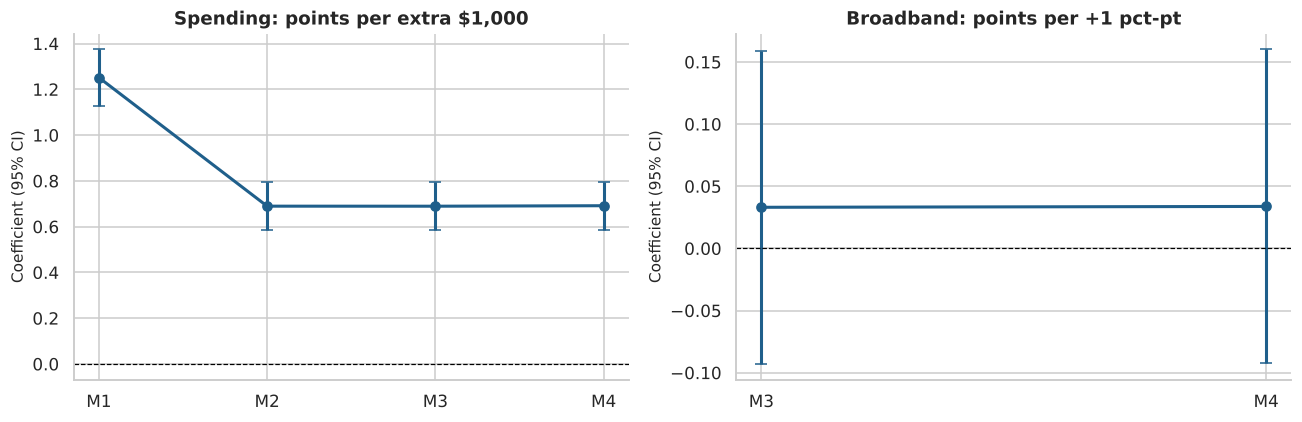

In [10]:
def pack(m, term):
    lo, hi = m.conf_int().loc[term]
    return [float(m.params[term]), float(lo), float(hi), float(m.pvalues[term])]

results['models'] = {name: {'r2': float(m.rsquared), 'adj_r2': float(m.rsquared_adj),
                            'ppe': pack(m, 'ppe_k'),
                            'frl': pack(m, 'percent_free_reduced_lunch') if 'percent_free_reduced_lunch' in m.params else None,
                            'bb': pack(m, 'broadband_access_pct') if 'broadband_access_pct' in m.params else None}
                     for name, m in robust.items()}
results['f_tests'] = ftests.set_index('step')[['F', 'p_value', 'R2_gain']].to_dict('index')

# Visual: how the key coefficients change as controls are added
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, term, lab in zip(axes, ['ppe_k', 'broadband_access_pct'], ['Spending: points per extra $1,000', 'Broadband: points per +1 pct-pt']):
    names = [nm for nm, m in robust.items() if term in m.params]
    est = [robust[nm].params[term] for nm in names]
    lo = [robust[nm].conf_int().loc[term, 0] for nm in names]
    hi = [robust[nm].conf_int().loc[term, 1] for nm in names]
    ax.errorbar(range(len(names)), est, yerr=[np.array(est) - lo, np.array(hi) - est], fmt='o-', capsize=4, color=PALETTE['primary'], lw=2)
    ax.axhline(0, color='black', lw=.8, ls='--')
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names); ax.set_title(lab); ax.set_ylabel('Coefficient (95% CI)')
plt.tight_layout(); save_fig('04_coefficients_across_models'); plt.show()

The left panel shows the spending coefficient shrinking but staying clearly positive; the right panel shows the broadband coefficient dropping to roughly zero as soon as poverty is included.

### The full M4 model

In [11]:
print(robust['M4'].summary().tables[1])

                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                           59.5798      7.291      8.172      0.000      45.290      73.869
C(locale_group)[T.Rural]             1.2478      0.720      1.732      0.083      -0.164       2.660
C(locale_group)[T.Suburban]          0.8984      0.497      1.806      0.071      -0.076       1.873
C(locale_group)[T.Town]              0.4019      0.701      0.573      0.566      -0.972       1.776
C(level)[T.High School]             -0.3862      0.595     -0.649      0.516      -1.552       0.780
C(level)[T.K-12 Combined]           -0.4931      0.916     -0.539      0.590      -2.288       1.302
C(level)[T.Middle School]           -0.1477      0.493     -0.300      0.765      -1.114       0.819
C(control)[T.Private Non-Profit]     0.7160      1.531      0.468      0.640      -2.284   

## 6. Standardised effects and multicollinearity

### 6.1 Standardised coefficients
Spending is measured in dollars and poverty in percentage points, so their raw coefficients cannot be compared directly. Standardising every variable (mean 0, sd 1) makes the coefficients "change in math proficiency, in standard deviations, per 1 sd change in the predictor", which allows a fair comparison.

In [12]:
zcols = ['math_proficiency_pct', 'ppe_k', 'percent_free_reduced_lunch', 'broadband_access_pct']
kz = k12[zcols].apply(stats.zscore)
mz = smf.ols('math_proficiency_pct ~ ppe_k + percent_free_reduced_lunch + broadband_access_pct', kz).fit(cov_type='HC3')
std_beta = mz.params.drop('Intercept').rename(index=key).to_frame('standardised_beta')
std_beta[['ci_low', 'ci_high']] = mz.conf_int().drop('Intercept').rename(index=key).values
display(std_beta.round(3))
results['std_beta'] = {'ppe': float(mz.params['ppe_k']), 'frl': float(mz.params['percent_free_reduced_lunch']), 'bb': float(mz.params['broadband_access_pct'])}

,standardised_beta,ci_low,ci_high
Spending ($1k),0.158,0.134,0.182
Poverty (1 pct-pt),-0.544,-0.579,-0.508
Broadband (1 pct-pt),0.009,-0.026,0.044


### 6.2 Multicollinearity (variance inflation factors)
Poverty and broadband are strongly correlated, which can make it hard to separate their individual effects. The VIF measures how much a coefficient's variance is inflated by correlation with the other predictors (rule of thumb: above 5 is worth attention, above 10 is a problem).

In [13]:
X3 = pd.DataFrame(plain['M3'].model.exog, columns=plain['M3'].model.exog_names)
vif3 = pd.Series({c: variance_inflation_factor(X3.values, i) for i, c in enumerate(X3.columns) if c != 'Intercept'}, name='VIF')
display(vif3.rename(index=key).round(2).to_frame())

print(f"Correlation between poverty and broadband: {k12['percent_free_reduced_lunch'].corr(k12['broadband_access_pct']):.2f}")
results['vif'] = {'ppe': float(vif3['ppe_k']), 'frl': float(vif3['percent_free_reduced_lunch']), 'bb': float(vif3['broadband_access_pct'])}

,VIF
Spending ($1k),1.06
Poverty (1 pct-pt),2.40
Broadband (1 pct-pt),2.34


Correlation between poverty and broadband: -0.76


**Reading.** All the VIFs are low (about 1 for spending and about 2.4 for poverty and broadband, well under the threshold of 5), so multicollinearity is **not** a problem here: the model can separate poverty from broadband, and the broadband coefficient is estimated with enough precision that its confidence interval rules out anything but a small adjusted association. That strengthens the finding. The honest limitation is about *interpretation*, not estimation: I can say broadband adds almost nothing *beyond* poverty, but I **cannot** say broadband access is unimportant, because it may be one of the channels through which disadvantage operates. It is mostly a marker of the same disadvantage.

## 7. Bootstrap confidence intervals

The HC3 intervals rely on large-sample theory. As a check that does not, I **resample schools with replacement** 2,000 times, refit M3 each time, and take the 2.5th and 97.5th percentiles of each coefficient.

,0.025,0.975,bootstrap_mean,HC3_ci_low,HC3_ci_high
Spending ($1k),0.586,0.795,0.689,0.586,0.793
Poverty (1 pct-pt),-0.413,-0.363,-0.389,-0.414,-0.363
Broadband (1 pct-pt),-0.093,0.158,0.033,-0.093,0.159


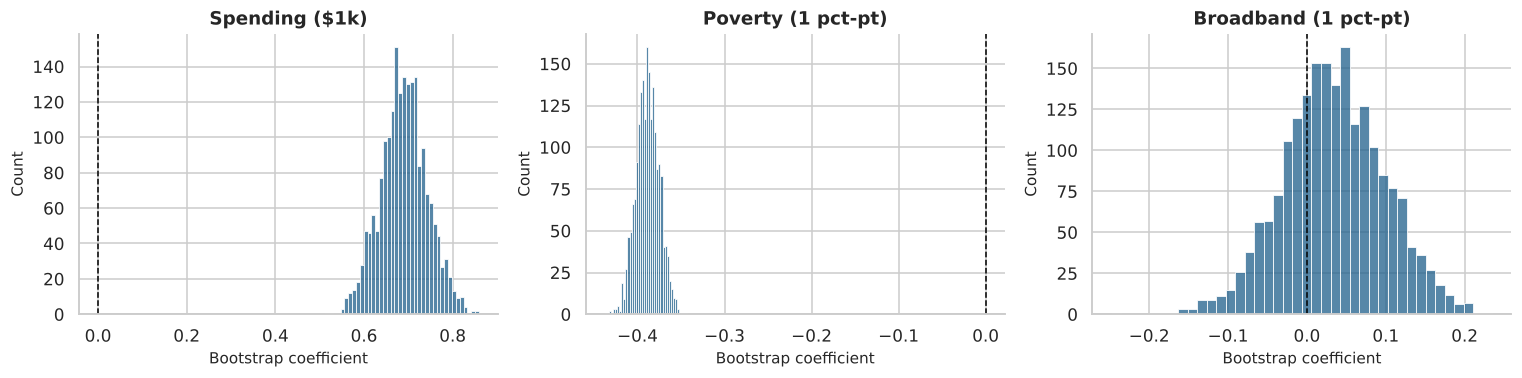

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
Xb = plain['M3'].model.exog
yb = plain['M3'].model.endog
names = plain['M3'].model.exog_names
B = 2000
boot = np.empty((B, Xb.shape[1]))
for b in range(B):
    idx = rng.integers(0, n, n)
    boot[b] = np.linalg.lstsq(Xb[idx], yb[idx], rcond=None)[0]
boot = pd.DataFrame(boot, columns=names)

ci = boot.quantile([0.025, 0.975]).T
ci['bootstrap_mean'] = boot.mean()
ci['HC3_ci_low'] = robust['M3'].conf_int()[0]
ci['HC3_ci_high'] = robust['M3'].conf_int()[1]
display(ci.drop(index='Intercept').rename(index=key).round(3))

results['bootstrap'] = {'ppe': [float(ci.loc['ppe_k', 0.025]), float(ci.loc['ppe_k', 0.975])],
                        'frl': [float(ci.loc['percent_free_reduced_lunch', 0.025]), float(ci.loc['percent_free_reduced_lunch', 0.975])],
                        'bb': [float(ci.loc['broadband_access_pct', 0.025]), float(ci.loc['broadband_access_pct', 0.975])]}

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, term, lab in zip(ax, ['ppe_k', 'percent_free_reduced_lunch', 'broadband_access_pct'], key.values()):
    sns.histplot(boot[term], bins=40, ax=a, color=PALETTE['primary'])
    a.axvline(0, color='black', ls='--', lw=1); a.set_title(lab); a.set_xlabel('Bootstrap coefficient')
plt.tight_layout(); save_fig('04_bootstrap_distributions'); plt.show()

**Reading.** The bootstrap intervals closely match the HC3 intervals, so the conclusions do not depend on the particular method of computing uncertainty. The spending and poverty distributions sit clearly away from zero, while the broadband distribution is centred near zero and straddles it: the adjusted broadband association is statistically indistinguishable from none.

## 8. Interaction: does the spending association depend on poverty?

In EDA the spending slope looked a little steeper in high-poverty schools. I test this with an interaction term (centring the variables so the main effects stay interpretable).

In [15]:
k12['ppe_c'] = k12['ppe_k'] - k12['ppe_k'].mean()
k12['frl_c'] = k12['percent_free_reduced_lunch'] - k12['percent_free_reduced_lunch'].mean()
mi = smf.ols('math_proficiency_pct ~ ppe_c * frl_c + broadband_access_pct', k12).fit(cov_type='HC3')
print(mi.summary().tables[1])

b_ppe, b_int = mi.params['ppe_c'], mi.params['ppe_c:frl_c']
frl_mean = k12['percent_free_reduced_lunch'].mean()
pts = {'10th percentile poverty': k12['percent_free_reduced_lunch'].quantile(.10),
       'median poverty': k12['percent_free_reduced_lunch'].median(),
       '90th percentile poverty': k12['percent_free_reduced_lunch'].quantile(.90)}
slopes = pd.Series({lab: b_ppe + b_int * (v - frl_mean) for lab, v in pts.items()}, name='spending slope (pts per $1k)')
display(slopes.round(3).to_frame())

results['interaction'] = {'coef': float(b_int), 'p': float(mi.pvalues['ppe_c:frl_c']),
                          'slope_low': float(slopes.iloc[0]), 'slope_mid': float(slopes.iloc[1]), 'slope_high': float(slopes.iloc[2])}

                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               55.7453      5.821      9.577      0.000      44.337      67.154
ppe_c                    0.7212      0.057     12.543      0.000       0.608       0.834
frl_c                   -0.3870      0.013    -29.844      0.000      -0.412      -0.362
ppe_c:frl_c              0.0033      0.002      1.580      0.114      -0.001       0.007
broadband_access_pct     0.0330      0.064      0.512      0.608      -0.093       0.159


,spending slope (pts per $1k)
10th percentile poverty,0.615
median poverty,0.725
90th percentile poverty,0.818


**Reading.** The interaction coefficient tells how the spending slope changes per extra point of poverty, and the table converts that into the spending slope at low, median and high poverty. The slope estimates rise a little with poverty, but the interaction is **not statistically significant** (p is above 0.05), so I do not have good evidence that spending is more strongly associated with math proficiency in poorer schools. The cautious conclusion is that the spending association is **similar across poverty levels**. The slight upward pattern is a hypothesis for further study, not a finding. Remember too that this is an **association**: schools that spend more may differ in other ways, and the data cannot tell me which dollars were spent on what.

## 9. Model diagnostics

Regression results are only trustworthy if the model's assumptions are reasonable. I check M4 (the fullest model).

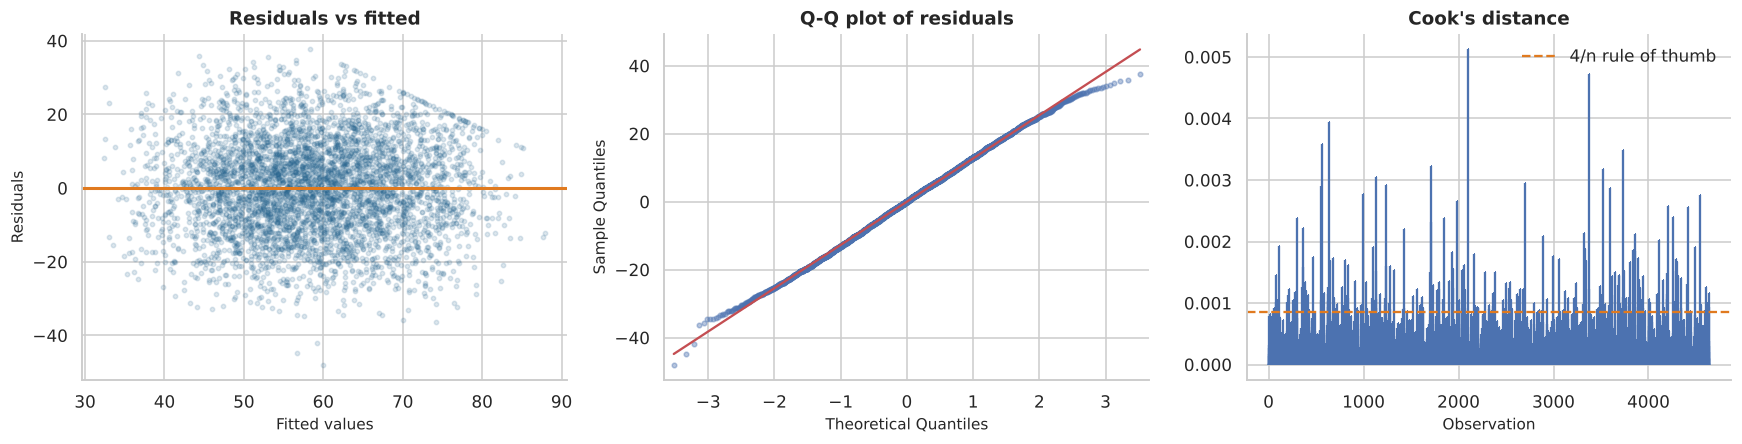

Breusch-Pagan test for heteroskedasticity: LM = 21.3, p = 0.213
Observations above the 4/n Cook threshold: 222 (4.8%); largest Cook distance = 0.0051
Residual skewness = -0.02; residual sd = 12.72 points


In [16]:
m4 = plain['M4']
resid, fitted = m4.resid, m4.fittedvalues
infl = m4.get_influence()
cooks = infl.cooks_distance[0]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(fitted, resid, alpha=.15, s=8, color=PALETTE['primary']); ax[0].axhline(0, color=PALETTE['accent'], lw=2)
ax[0].set_xlabel('Fitted values'); ax[0].set_ylabel('Residuals'); ax[0].set_title('Residuals vs fitted')
sm.qqplot(resid, line='s', ax=ax[1], markersize=3, alpha=.4); ax[1].set_title('Q-Q plot of residuals')
ax[2].stem(np.arange(n), cooks, markerfmt=',', basefmt=' '); ax[2].axhline(4 / n, color=PALETTE['accent'], ls='--', label='4/n rule of thumb')
ax[2].set_title("Cook's distance"); ax[2].set_xlabel('Observation'); ax[2].legend(frameon=False)
plt.tight_layout(); save_fig('04_model_diagnostics'); plt.show()

bp = het_breuschpagan(resid, m4.model.exog)
print(f'Breusch-Pagan test for heteroskedasticity: LM = {bp[0]:.1f}, p = {bp[1]:.3g}')
print(f'Observations above the 4/n Cook threshold: {(cooks > 4 / n).sum()} ({(cooks > 4 / n).mean():.1%}); largest Cook distance = {cooks.max():.4f}')
print(f'Residual skewness = {stats.skew(resid):.2f}; residual sd = {resid.std():.2f} points')
results['diagnostics'] = {'bp_p': float(bp[1]), 'max_cooks': float(cooks.max()), 'n_cooks_flag': int((cooks > 4 / n).sum()), 'resid_sd': float(resid.std())}

**Reading.**
- **Residuals vs fitted:** an even band around zero with no curve and no funnel shape, so a linear form is reasonable and the spread of errors is fairly constant.
- **Q-Q plot:** residuals follow the line closely, with only a slight thinning in the upper tail that matches the 96% ceiling on math proficiency. Normal-based intervals are reasonable (and the bootstrap confirms them).
- **Cook's distance:** the largest value is about 0.005, far below 1 (the usual concern level), so no single school dominates the fit.
- **Breusch-Pagan:** the p-value is above 0.05, so there is no evidence of heteroskedasticity. I keep robust (HC3) errors as a cautious default, and they give almost identical intervals to the classical ones.
- **Residual spread:** the typical prediction error is about 12.7 percentage points of math proficiency. That is the amount of school-to-school variation these variables do **not** explain, which becomes important in the machine-learning notebook.

## 10. Robustness checks

A finding is stronger if it survives reasonable changes to the sample and the specification. The first row is the baseline (M3); I then re-estimate under 11 alternative specifications. (In the Title I row I *replace* `control` with Title I status because the two are perfectly collinear: Title I "Not Applicable" is exactly the set of private schools.)

In [17]:
def coefs(data, formula=f3, cluster=False):
    if cluster:
        m = smf.ols(formula, data).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(data['state_code'])[0]})
    else:
        m = smf.ols(formula, data).fit(cov_type='HC3')
    ci = m.conf_int()
    out = {}
    for t, nm in [('ppe_k', 'ppe'), ('broadband_access_pct', 'bb'), ('percent_free_reduced_lunch', 'frl')]:
        out[nm] = (m.params[t], ci.loc[t, 0], ci.loc[t, 1], m.pvalues[t])
    return out, int(m.nobs), m.rsquared

specs = {
    'All K-12 schools (M3)': (k12, f3),
    'Full controls (M4)': (k12, f4),
    # Title I 'Not Applicable' coincides exactly with private control, so control and Title I are perfectly
    # collinear. I therefore REPLACE control with Title I status here instead of adding it on top.
    'Replace control with Title I status in M4 (the two overlap)': (k12, f3 + controls.replace(' + C(control)', '') + ' + C(title_i_status)'),
    'Exclude spending outliers': (k12[~k12['ppe_outlier_flag']], f3),
    'Exclude private non-profit/religious schools and reading/math-capped rows': (k12[~(k12['private_fixed_funding_flag'] | k12['reading_capped_flag'] | k12['math_capped_flag'])], f3),
    'Exclude ratio-mismatch rows': (k12[~k12['str_mismatch_flag']], f3),
    'Public schools only': (k12[k12['control'] == 'Public'], f3),
    'State-clustered standard errors (51 states)': (k12, f3, True),
}
for lvl in ['Elementary School', 'Middle School', 'High School', 'K-12 Combined']:
    specs[f'Level: {lvl}'] = (k12[k12['level'] == lvl], f3)

rows = []
for name, spec in specs.items():
    d, f = spec[0], spec[1]
    c, nobs, r2 = coefs(d, f, cluster=len(spec) > 2)
    rows.append({'specification': name, 'n': nobs, 'R2': r2,
                 'ppe_coef': c['ppe'][0], 'ppe_lo': c['ppe'][1], 'ppe_hi': c['ppe'][2],
                 'bb_coef': c['bb'][0], 'bb_lo': c['bb'][1], 'bb_hi': c['bb'][2],
                 'frl_coef': c['frl'][0]})
robust_tbl = pd.DataFrame(rows)
display(robust_tbl.round(3))
results['robustness'] = robust_tbl.to_dict('records')
results['robustness_ranges'] = {'ppe_min': float(robust_tbl['ppe_coef'].min()), 'ppe_max': float(robust_tbl['ppe_coef'].max()),
                                'bb_min': float(robust_tbl['bb_coef'].min()), 'bb_max': float(robust_tbl['bb_coef'].max())}

,specification,n,R2,ppe_coef,ppe_lo,ppe_hi,bb_coef,bb_lo,bb_hi,frl_coef
0,All K-12 schools (M3),4642,0.369,0.689,0.586,0.793,0.033,-0.093,0.159,-0.388
1,Full controls (M4),4642,0.371,0.692,0.587,0.796,0.034,-0.093,0.160,-0.381
2,Replace control with Title I status in M4 (the...,4642,0.371,0.690,0.586,0.795,0.034,-0.093,0.160,-0.388
3,Exclude spending outliers,4575,0.357,0.703,0.588,0.818,0.035,-0.092,0.162,-0.388
4,Exclude private non-profit/religious schools a...,3954,0.304,0.745,0.609,0.881,-0.005,-0.137,0.127,-0.380
5,Exclude ratio-mismatch rows,4572,0.367,0.689,0.584,0.793,0.026,-0.102,0.154,-0.389
6,Public schools only,3315,0.314,0.785,0.633,0.937,0.024,-0.123,0.171,-0.387
7,State-clustered standard errors (51 states),4642,0.369,0.689,0.574,0.805,0.033,-0.101,0.167,-0.388
8,Level: Elementary School,2225,0.353,0.626,0.471,0.780,0.024,-0.162,0.211,-0.393
9,Level: Middle School,996,0.409,0.761,0.558,0.965,0.025,-0.230,0.281,-0.383


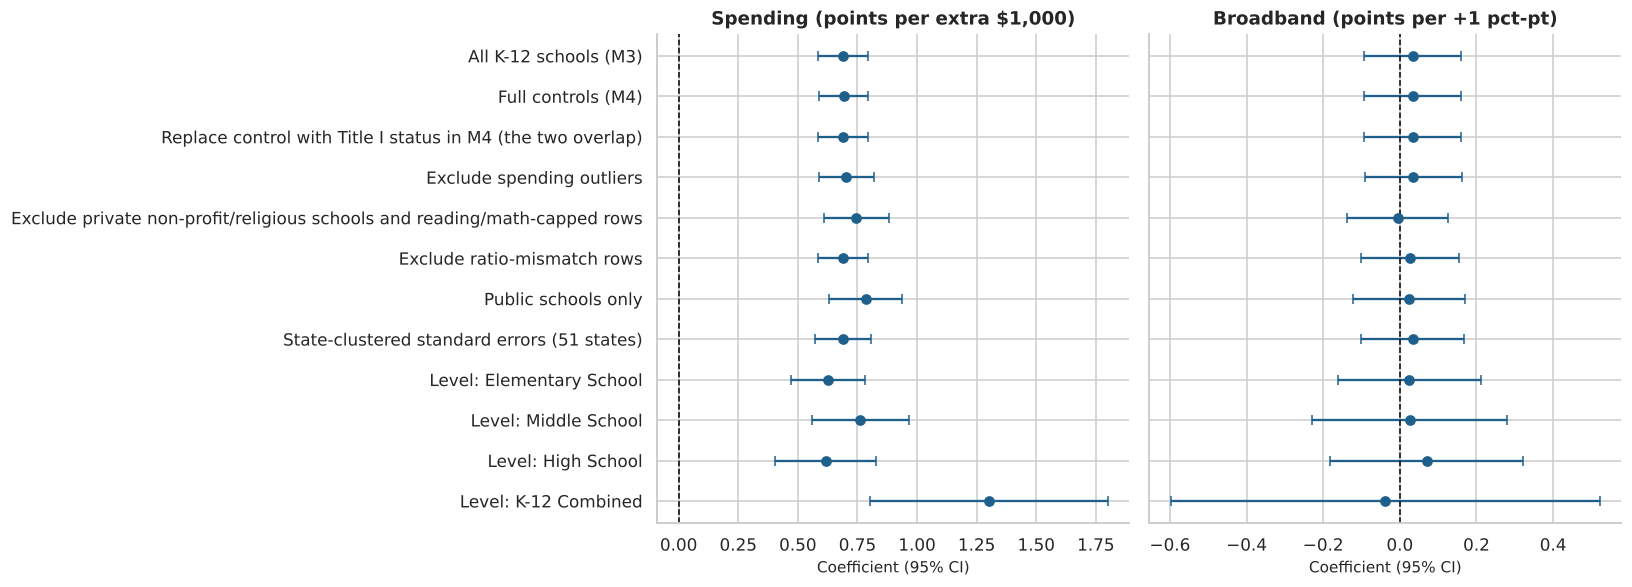

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
ypos = np.arange(len(robust_tbl))[::-1]
for ax, pre, title in zip(axes, ['ppe', 'bb'], ['Spending (points per extra $1,000)', 'Broadband (points per +1 pct-pt)']):
    ax.errorbar(robust_tbl[f'{pre}_coef'], ypos,
                xerr=[robust_tbl[f'{pre}_coef'] - robust_tbl[f'{pre}_lo'], robust_tbl[f'{pre}_hi'] - robust_tbl[f'{pre}_coef']],
                fmt='o', capsize=3, color=PALETTE['primary'])
    ax.axvline(0, color='black', ls='--', lw=1)
    ax.set_yticks(ypos); ax.set_yticklabels(robust_tbl['specification']); ax.set_title(title); ax.set_xlabel('Coefficient (95% CI)')
plt.tight_layout(); save_fig('04_robustness_forest'); plt.show()

**Reading the forest plot.** Each row is a different sample or specification. The spending coefficient stays positive and its interval stays away from zero in every row (it is noisier in the small K-12 Combined group, as expected with about 200 schools). The broadband interval stays close to zero throughout. The conclusions therefore do **not** hinge on outliers, the private fixed-funding schools and capped values, the ratio mismatches, one school level, the choice of controls, or the assumption that schools are independent (the state-clustered row allows schools in the same state to be correlated, and the intervals barely change).

## 11. Summary of statistical findings

In [19]:
m = results['models']
print('=== STATISTICAL FINDINGS (all numbers computed above) ===\n')
print(f"1. POVERTY dominates. Correlation with math proficiency r = {results['corr']['percent_free_reduced_lunch']['pearson']:.2f}; "
      f"adding poverty lifts R-squared from {m['M1']['r2']:.2f} to {m['M2']['r2']:.2f}. Standardised beta = {results['std_beta']['frl']:.2f}.")
print(f"\n2. SPENDING survives. Raw coefficient {m['M1']['ppe'][0]:.2f} points per $1k falls to {m['M3']['ppe'][0]:.2f} after controlling for poverty and broadband "
      f"(95% CI {m['M3']['ppe'][1]:.2f} to {m['M3']['ppe'][2]:.2f}; bootstrap {results['bootstrap']['ppe'][0]:.2f} to {results['bootstrap']['ppe'][1]:.2f}), "
      f"i.e. about {(1 - m['M3']['ppe'][0] / m['M1']['ppe'][0]):.0%} of the raw association was poverty.")
print(f"\n3. BROADBAND does not survive. Correlation r = {results['corr']['broadband_access_pct']['pearson']:.2f}, but the adjusted coefficient is "
      f"{m['M3']['bb'][0]:.3f} (95% CI {m['M3']['bb'][1]:.3f} to {m['M3']['bb'][2]:.3f}, p = {m['M3']['bb'][3]:.2f}); R-squared gain from adding it = {results['f_tests']['M2 -> M3 (add broadband)']['R2_gain']:.4f}.")
print(f"\n4. TITLE I groups differ strongly (eta-squared = {results['title1']['eta2']:.2f}), mirroring the poverty gradient.")
print(f"\n5. The broadband gap is mainly a POVERTY gap: poverty explains {results['locale_broadband']['poverty_r2']:.0%} of broadband variation, locale only {results['locale_broadband']['eta2']:.1%}.")
print(f"\n6. Interaction: spending slope is {results['interaction']['slope_low']:.2f} (low poverty), {results['interaction']['slope_mid']:.2f} (median), "
      f"{results['interaction']['slope_high']:.2f} (high poverty) points per $1k; interaction p = {results['interaction']['p']:.3f}.")
print(f"\n7. ROBUST: the spending coefficient stays between {results['robustness_ranges']['ppe_min']:.2f} and {results['robustness_ranges']['ppe_max']:.2f} across all specifications.")

save_json(results, 'stats_results')
print('\nSaved reports/results/stats_results.json for notebook 06.')

=== STATISTICAL FINDINGS (all numbers computed above) ===

1. POVERTY dominates. Correlation with math proficiency r = -0.59; adding poverty lifts R-squared from 0.08 to 0.37. Standardised beta = -0.54.

2. SPENDING survives. Raw coefficient 1.25 points per $1k falls to 0.69 after controlling for poverty and broadband (95% CI 0.59 to 0.79; bootstrap 0.59 to 0.79), i.e. about 45% of the raw association was poverty.

3. BROADBAND does not survive. Correlation r = 0.45, but the adjusted coefficient is 0.033 (95% CI -0.093 to 0.159, p = 0.61); R-squared gain from adding it = 0.0000.

4. TITLE I groups differ strongly (eta-squared = 0.22), mirroring the poverty gradient.

5. The broadband gap is mainly a POVERTY gap: poverty explains 57% of broadband variation, locale only 9.1%.

6. Interaction: spending slope is 0.62 (low poverty), 0.72 (median), 0.82 (high poverty) points per $1k; interaction p = 0.114.

7. ROBUST: the spending coefficient stays between 0.62 and 1.30 across all specificat

### What the statistics establish, and what they do not

**They support:** after accounting for poverty, higher per-pupil spending is still associated with higher math proficiency, while broadband access adds little beyond poverty.

**They do not support:**
- **Causation.** This is observational, cross-sectional data. A school may spend more *because* it is already high-performing or located in a wealthy tax base. The coefficient is "association after adjustment", not "effect of spending".
- **"Broadband doesn't matter."** Broadband is so tied to poverty that its separate contribution cannot be isolated with this data.
- **Statements about individual students.** The unit is the school; school-level patterns do not necessarily hold for individual children (the ecological fallacy).

**Next → `05_machine_learning.ipynb`:** how well can school characteristics *predict* math proficiency, and which features does a model rely on?